<center><h1>Process the PSS Network</h1></center><hr/>

This notebook parses the PSS (Pathway Simulation System) network XML file and extracts:
- **Species**: biological entities (genes, proteins, metabolites, etc.) with their compartment and type
- **Reactions**: interactions between species (reactants, products, modifiers)

Results are saved as JSON files for downstream use.

In [1]:
from scripts.utils import (
    PSS_NETWORK_PATH,
    PSS_REACTIONS_PATH,
    PSS_SPECIES_PATH,
    BeautifulSoup,
    RED,
    RESET,
    plt,
    sns,
    np,
    json,
)

## Species Type Mapping

PSS encodes the biological type of each species as a suffix in its ID (e.g. `_p` = protein, `_g` = gene).
The mapping below translates those codes to human-readable labels.

In [2]:
# Maps the species ID suffix to a biological type label.
# IDs have the form: s_<name>_<compartment>_<type>[_<index>]
# The type suffix is the last non-numeric segment.
SPECIE_TYPE = {
    'ab':   'abiotic',
    'abst': 'foreign_entity',
    'absta':'foreign_entity',
    'c':    'complex',
    'ca':   'complex_active',
    'f':    'foreign_entity',
    'g':    'gene',
    'm':    'metabolite',
    'mi':   'mirna',
    'mr':   'mrna',
    'nc':   'ncrna',
    'p':    'protein',
    'pa':   'protein_active',
    'pr':   'process',
    'pra':  'process_active',
}


def get_specie_type(specie: dict) -> str:
    """Return the biological type of a species from its ID suffix.

    The ID may optionally end with a numeric index (e.g. `_p_1`),
    in which case the type code is the second-to-last segment.

    Args:
        specie: A BeautifulSoup tag with an 'id' attribute.

    Returns:
        A human-readable type string from SPECIE_TYPE.
    """
    segments = specie['id'].split('_')
    type_code = segments[-1] if not segments[-1].isdigit() else segments[-2]
    return SPECIE_TYPE[type_code]

## Parse the PSS Network XML

In [3]:
with open(PSS_NETWORK_PATH, 'r') as f:
    pss = BeautifulSoup(f.read(), 'xml')

## Extract Species

In [4]:
species = {
    specie['id']: {
        'name':        specie['name'],
        'compartment': specie['compartment'],
        'type':        get_specie_type(specie),
    }
    for specie in pss.find_all('species')
}

print(f'Found {RED}{len(species)}{RESET} species in the PSS network.')

Found 1139 species in the PSS network.


> ✅ Checked against species in the XML file — count confirmed correct.

## Extract Reactions

In [5]:
def get_species_list(reaction, tag: str, ref: str) -> list:
    """Extract species IDs from a reaction section (reactants, products, or modifiers).

    Args:
        reaction:  A BeautifulSoup reaction tag.
        tag:       The enclosing list tag (e.g. 'listOfReactants').
        ref:       The child reference tag (e.g. 'speciesReference').

    Returns:
        A list of species ID strings, or an empty list if the section is absent.
    """
    section = reaction.find(tag)
    return [s['species'] for s in section.find_all(ref)] if section else []


def get_reaction_info(reaction) -> dict:
    """Build a structured summary of a single reaction.

    Returns:
        A dict with keys 'reactants', 'products', and 'modifiers',
        each containing a list of species IDs.
    """
    return {
        'reactants': get_species_list(reaction, 'listOfReactants', 'speciesReference'),
        'products':  get_species_list(reaction, 'listOfProducts',  'speciesReference'),
        'modifiers': get_species_list(reaction, 'listOfModifiers',  'modifierSpeciesReference'),
    }

In [6]:
reactions = {
    reaction['id']: get_reaction_info(reaction)
    for reaction in pss.find_all('reaction')
}

In [7]:
# Sanity-check: print the first reaction as an example
first_id = next(iter(reactions))
print(f'Example — reaction {RED}{first_id}{RESET}:')
reactions[first_id]

Example — reaction rx00669:


{'reactants': ['s_VPg_cyt_p', 's_LHB1B1_cyt_p'],
 'products': ['s_LHB1B1VPg_cyt_c'],
 'modifiers': []}

## Visualise Species Distributions

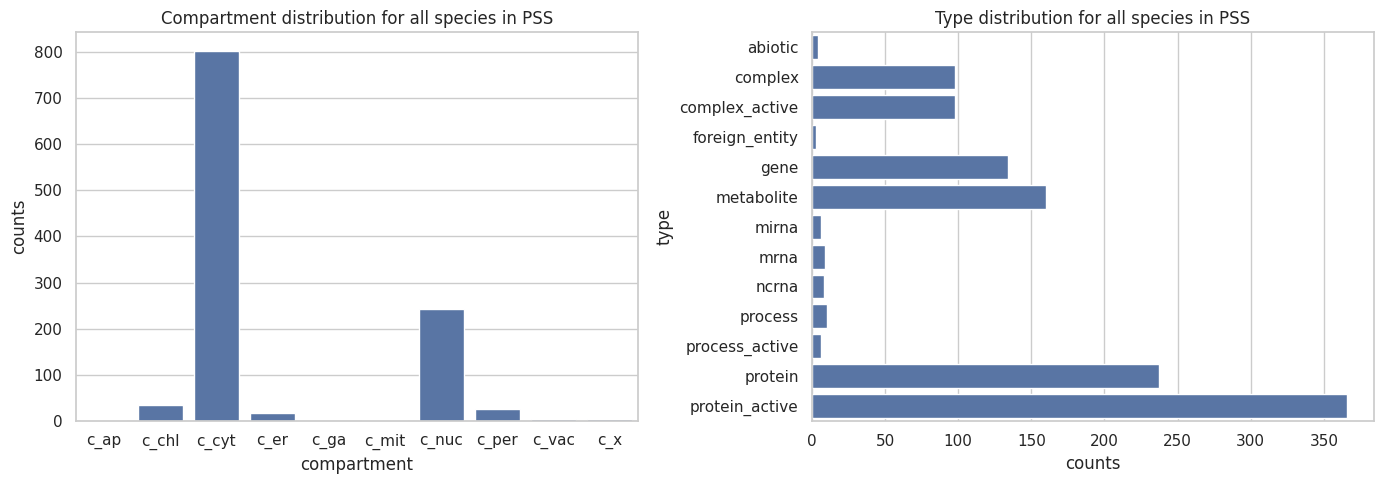

In [8]:
compartments = [species[s]['compartment'] for s in species]
types        = [species[s]['type']        for s in species]

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5))

comp_labels, comp_counts = np.unique(compartments, return_counts=True)
sns.barplot(
    data={'compartment': comp_labels, 'counts': comp_counts},
    x='compartment', y='counts',
    ax=ax_left,
)
ax_left.set_title('Compartment distribution for all species in PSS')

type_labels, type_counts = np.unique(types, return_counts=True)
sns.barplot(
    data={'type': type_labels, 'counts': type_counts},
    x='counts', y='type',
    ax=ax_right,
)
ax_right.set_title('Type distribution for all species in PSS')

plt.tight_layout()
plt.show()

## Save Outputs

In [9]:
with open(PSS_REACTIONS_PATH, 'w') as f:
    json.dump(reactions, f)

with open(PSS_SPECIES_PATH, 'w') as f:
    json.dump(species, f)

print('Saved reactions →', PSS_REACTIONS_PATH)
print('Saved species   →', PSS_SPECIES_PATH)

Saved reactions → /home/ratanasoski/Desktop/Master_Thesis/ThesisRepository/data_/processed/pss_reactions.json
Saved species   → /home/ratanasoski/Desktop/Master_Thesis/ThesisRepository/data_/processed/pss_species.json
